In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_absolute_error,mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

In [157]:
import os
os.getcwd()

'/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/notebook'

In [158]:
ratings=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/ratings.csv")
movies=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/movies.csv")
users=pd.read_csv("/Users/akhichoudhary/Foundation & Advanced ML/Recommender system/data/raw/users.csv")

In [159]:
print(ratings.columns)
print(movies.columns)
print(users.columns)

Index(['user_id', 'movie_id', 'rating', 'timestamp'], dtype='object')
Index(['movie_id', 'title', 'genre'], dtype='object')
Index(['user_id', 'age', 'gender', 'occupation', 'zip_code'], dtype='object')


In [160]:
max_rating = ratings.rating.max()
min_rating = ratings.rating.min()
num_ratings = len(ratings)
num_users = ratings.user_id.nunique()
num_movies = ratings.movie_id.nunique()
print(f'The number of ratings : {num_ratings}')
print(f'The number of unique users : {num_users}')
print(f'The number of unique movies : {num_movies}')
# this rating part if written better or is okay??
print(f'The rating scale from min : {min_rating} to {max_rating}')

The number of ratings : 100000
The number of unique users : 943
The number of unique movies : 1682
The rating scale from min : 1 to 5


### What the profile numbers mean

| | Count of ratings | Mean of ratings |
|---|---|---|
| **Per user** | How active the user is | How generous the user is |
| **Per movie** | How popular the movie is, and how much evidence we have | How well liked the movie is |

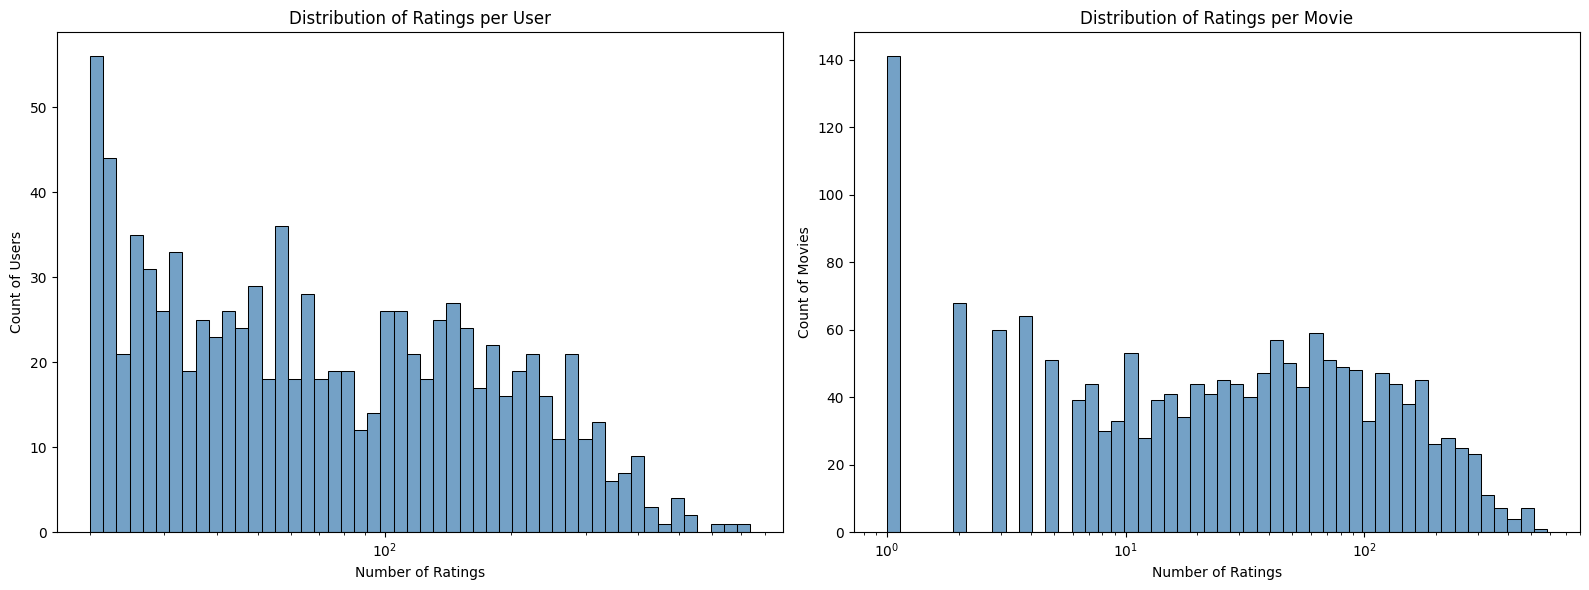

In [161]:
ratings_per_user = ratings.groupby('user_id')['rating'].count()
ratings_per_movie = ratings.groupby('movie_id')['rating'].count()
## for mean and median 
mean_rating_per_movie = ratings.groupby('movie_id')['rating'].mean()
median_rating_per_movie = ratings.groupby('movie_id')['rating'].median()

### better visually appealing graph design should be simple to code as well or its fine
# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(ratings_per_user, bins=50, ax=axes[0], color='steelblue',log_scale=True)
axes[0].set_title('Distribution of Ratings per User')
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Count of Users')

sns.histplot(ratings_per_movie, bins=50, ax=axes[1], color='steelblue',log_scale=True)
axes[1].set_title('Distribution of Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Count of Movies')

plt.tight_layout()
plt.show()

### Sparsity: how much of the picture do we actually see?

Picture a giant spreadsheet. Each row is a member and each column is a movie. A cell is
filled only if that member rated that movie.

- 943 members x 1,682 movies = about 1.59 million cells
- Only 100,000 are filled, which is **6.3%**
- The other **93.7% are unknown**

**Why a missing rating is not a zero:** the scale runs from 1 to 5, so 0 is not a valid
rating. A blank means "we do not know", not "the member disliked it". They may simply
not have seen the movie. Treating blanks as zeros would pull averages down and make
unrelated members look similar.

**What sparsity means for our methods:** to compare two members we need movies both
have rated. With only 6.3% of the grid filled, most pairs share very few movies, so
similarities are noisy and some predictions cannot be made at all. Those fall back to a
simple average. Predicting the blank 93.7% is exactly the product's job.

In [162]:

density = num_ratings / (num_users * num_movies)
print(f"Density: {density:.2%}")

Density: 6.30%


In [163]:
# Size check and splitting data into 80/20 then further  80 into 80/20
outer_train_df,test_df = train_test_split(ratings,test_size=0.2,random_state=42)
fitting_df,validation_df = train_test_split(outer_train_df,test_size=0.2,random_state=42)
print('Number of rows in outer_train',len(outer_train_df))
print('Number of rows in test_df',len(test_df))
print('Number of rows in fitting_df',len(fitting_df))
print('Number of rows in validation_df',len(validation_df))
print(len(test_df)+len(fitting_df)+len(validation_df))

Number of rows in outer_train 80000
Number of rows in test_df 20000
Number of rows in fitting_df 64000
Number of rows in validation_df 16000
100000


In [164]:
# Dropping unseen users and movies
## why we do so?
# my understanding because density is 6.30% and we will train basis that only as these are of main use rest we dont have any idea
known_users_fit = set(fitting_df['user_id'].unique())
known_movies_fit = set(fitting_df['movie_id'].unique())
## why we used set here?

validation_filtered_df = validation_df[
    validation_df['user_id'].isin(known_users_fit)&
    validation_df['movie_id'].isin(known_movies_fit)
].copy()


known_users_outer = set(outer_train_df['user_id'].unique())
known_movies_outer = set(outer_train_df['movie_id'].unique())

test_filtered_df = test_df[
    test_df['user_id'].isin(known_users_outer)&
    test_df['movie_id'].isin(known_movies_outer)
].copy()

fitting_matrix=fitting_df.pivot(index='user_id',columns='movie_id',values='rating')
fitting_matrix




movie_id,1,2,3,4,5,6,7,8,9,10,...,1666,1670,1671,1672,1673,1676,1678,1679,1680,1681
user_id,,,,,,,,,,,,,,,,,,,,,
1,NaN,3.0,NaN,NaN,3.0,NaN,4.0,NaN,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
940,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
941,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [165]:
print(len(fitting_df), len(validation_df), len(test_df))        # 64000 16000 20000

print(f"validation rows: {len(validation_df)} -> {len(validation_filtered_df)} "
      f"(dropped {len(validation_df) - len(validation_filtered_df)})")   # 16000 -> 15964 (dropped 36)
print(f"test rows: {len(test_df)} -> {len(test_filtered_df)} "
      f"(dropped {len(test_df) - len(test_filtered_df)})")               # 20000 -> 19969 (dropped 31)

print("fitting matrix shape:", fitting_matrix.shape)                      # (943, 1620)
print(f"filled share: {fitting_matrix.notna().mean().mean():.2%}")        # 4.19%


64000 16000 20000
validation rows: 16000 -> 15964 (dropped 36)
test rows: 20000 -> 19969 (dropped 31)
fitting matrix shape: (943, 1620)
filled share: 4.19%


The PDF's Section B asks you to explain one difference between the two. The split we made is random: rows are picked at random, so the fitting set contains a mix of old and new ratings, and so does the test set.
- Random holdout: the model can learn from ratings made after the ones it predicts. That is looking into the future. It's easy and stable, but it can give flattering scores.
- Chronological evaluation: train on earlier ratings and test on later ones, using the timestamp column. This mimics real use, where today's recommendations only know the past. Scores are usually lower, and more honest for a streaming service.

In [166]:
# Baseline 1 - The global mean
# Baseline 2 - The movie mean

global_mean = fitting_df['rating'].mean()
movie_mean = fitting_df.groupby('movie_id')['rating'].mean()

pred_global = pd.Series(global_mean, index=validation_filtered_df.index)
pred_movies = validation_filtered_df['movie_id'].map(movie_mean).fillna(global_mean)

predictions = {
    "global mean": pred_global,
    "movie mean": pred_movies,
}

actual = validation_filtered_df['rating']

results = []
for name, pred in predictions.items():
    rmse = mean_squared_error(actual, pred) ** 0.5   # no trailing comma
    mae = mean_absolute_error(actual, pred)
    results.append({"model": name, "RMSE": rmse, "MAE": mae})

pd.DataFrame(results).round(2)

,model,RMSE,MAE
0,global mean,1.12,0.94
1,movie mean,1.03,0.82


# user-user cosine
- First neighborhood model

In [ ]:
sim=cosine_similarity(fitting_matrix.fillna(0))
sim_df=pd.DataFrame(sim,index=fitting_matrix.index,columns=fitting_matrix.index)
sim_df


array([[1.        , 0.13840654, 0.03560417, ..., 0.08111219, 0.07523711,
        0.26994659],
       [0.13840654, 1.        , 0.10037317, ..., 0.14450467, 0.15203785,
        0.0739164 ],
       [0.03560417, 0.10037317, 1.        , ..., 0.02761413, 0.0993085 ,
        0.        ],
       ...,
       [0.08111219, 0.14450467, 0.02761413, ..., 1.        , 0.08654036,
        0.1184763 ],
       [0.07523711, 0.15203785, 0.0993085 , ..., 0.08654036, 1.        ,
        0.1259357 ],
       [0.26994659, 0.0739164 , 0.        , ..., 0.1184763 , 0.1259357 ,
        1.        ]], shape=(943, 943))

In [168]:
# Cell: top 5 neighbors of the busiest user, plus sanity checks
user_id = fitting_matrix.notna().sum(axis=1).idxmax()   # user with most ratings
top5 = sim_df.loc[user_id].drop(user_id).nlargest(5)    # drop self, keep 5 most similar
print(top5)

print("diagonal is 1:", np.allclose(np.diag(sim), 1))
print("symmetric:    ", np.allclose(sim, sim.T))

user_id
846    0.356336
437    0.348554
222    0.337625
749    0.336617
301    0.334403
Name: 405, dtype: float64
diagonal is 1: True
symmetric:     True


In [169]:
# Overlap is the number of movies two users have both rated.
# Cosine similarity can't tell whether its score came from 1 shared movie or 100.
overlap = fitting_matrix.notna().astype(int)
#  overlap.T @ overlap would be the movie-movie version. We'll use that for item-item models later.
overlap_df = overlap@overlap.T
# (np.diag(overlap_df) == fitting_matrix.notna().sum(axis=1)).all()
np.array_equal(np.diag(overlap_df), fitting_matrix.notna().sum(axis=1))
overlap_df.loc[user_id,top5.index]

user_id
846    118
437     82
222     97
749     81
301     71
Name: 405, dtype: int64

In [170]:
# fitting_matrix.sub(fitting_matrix.mean(axis=1))
user_means = fitting_matrix.mean(axis = 1)
centered = fitting_matrix.sub(user_means,axis = 0)
centered.mean(axis = 1)
# np.allclose(centered.mean(axis=1),0)

user_id
1      1.722528e-16
2      1.869849e-16
3      7.970832e-17
4     -2.960595e-16
5      2.061843e-16
           ...     
939    2.960595e-16
940    1.044916e-16
941   -2.960595e-16
942    5.027425e-17
943    3.116416e-17
Length: 943, dtype: float64

In [ ]:


# user_id = 864
# movie_id = 143

# # 1. user's rows (name them, so later lines stay short)
# sim_row     = sim_df.loc[user_id]
# overlap_row = overlap_df.loc[user_id]

# # 2. mask (you already have it; rewrite using sim_row / overlap_row)
# mask=(sim_row.index!=user_id)&(fitting_matrix[movie_id].notna())&(sim_row>0)&(overlap_row>=3)

# # 3. neighbors: similarities of users who pass, best 20
# eligible  = sim_row[mask]           
# neighbors = eligible.nlargest(20) 
# print(len(eligible), len(neighbors))

# # 4. neighbors' centered ratings for this movie
# their_ratings = centered.loc[neighbors.index,movie_id]   
# # 5. weighted adjustment
# adjustment = (neighbors * their_ratings).sum() / neighbors.sum()

# # 6. prediction
# prediction = user_means.loc[user_id] + adjustment
# prediction = np.clip(prediction, 1, 5)

# # 7. compare with the real rating
# actual = validation_filtered_df.loc[
#     (validation_filtered_df["user_id"] == user_id)
#     & (validation_filtered_df["movie_id"] == movie_id),
#     "rating",
# ].iloc[0]
# print(len(neighbors), prediction, actual)


140 20
20 3.9689298797223125 4


In [172]:
movie_means = fitting_df.groupby("movie_id")["rating"].mean()


def predict_user_user(user_id, movie_id, k=20, min_overlap=3):
    """Return (prediction, used_fallback) for one user and movie."""
    # 1. this user's similarity and overlap with everyone
    sim_row = sim_df.loc[user_id]
    overlap_row = overlap_df.loc[user_id]

    # 2. who qualifies: not self, rated the movie, positive similarity, enough overlap
    mask = (
        (sim_row.index != user_id)
        & fitting_matrix[movie_id].notna()
        & (sim_row > 0)
        & (overlap_row >= min_overlap)
    )

    # 3. best k qualifying neighbors
    neighbors = sim_row[mask].nlargest(k)
    if neighbors.empty:
        return movie_means.loc[movie_id], True   # fallback to the movie mean

    # 4. neighbors' centered ratings for this movie
    their_ratings = centered.loc[neighbors.index, movie_id]

    # 5. similarity-weighted average of those centered ratings
    adjustment = (neighbors * their_ratings).sum() / neighbors.sum()

    # 6. start from the user's usual level, clip to 1-5
    prediction = np.clip(user_means.loc[user_id] + adjustment, 1, 5)
    return prediction, False


In [173]:
# The tests to run next:
print(predict_user_user(864, 143))        # expect (about 3.76, False)

# fallback pair: pick a rarely rated movie and a user who has not rated it
rare_movie = fitting_matrix.notna().sum().nsmallest(5).index[0]
rare_users = fitting_matrix.index[fitting_matrix[rare_movie].isna()]
print(predict_user_user(rare_users[0], rare_movie), movie_means.loc[rare_movie])


(np.float64(3.9689298797223125), False)
(np.float64(3.8076708039807667), False) 4.0


In [200]:
predictions = []
fallback_flags = []
actual = validation_filtered_df['rating']
for row in validation_filtered_df.itertuples():
    pred,used_fallback = predict_user_user(row.user_id, row.movie_id, k=20, min_overlap=3)
    predictions.append(pred)
    fallback_flags.append(used_fallback)
# Cell 1: per-row table (for checking), then overall scores on ALL rows
flags = np.array(fallback_flags)                  # True = used the movie-mean fallback
preds = np.array(predictions)
actual_arr = actual.to_numpy()

row_table = pd.DataFrame({
    "user_id": validation_filtered_df["user_id"].to_numpy(),
    "movie_id": validation_filtered_df["movie_id"].to_numpy(),
    "actual": actual_arr,
    "prediction": preds,
    "used_fallback": flags,
})

rmse_all = mean_squared_error(actual_arr, preds) ** 0.5
mae_all = mean_absolute_error(actual_arr, preds)
coverage = 1 - flags.mean()                       # share predicted by neighbors

print(f"overall RMSE {rmse_all:.3f} | MAE {mae_all:.3f} | coverage {coverage:.3f}")
row_table.head()

# Cell 2: summary table, one row per model (baselines are on the same validation rows)
summary = pd.DataFrame([
    {"model": "global mean",       "RMSE": 1.119,    "MAE": 0.940,   "coverage": 1.0},
    {"model": "movie mean",        "RMSE": 1.030,    "MAE": 0.822,   "coverage": 1.0},
    {"model": "user-user cosine",  "RMSE": rmse_all,  "MAE": mae_all, "coverage": coverage},
]).round(3)
summary

# Cell 3: where the error comes from (neighbor rows vs fallback rows)
parts = []
for name, rows in [("neighbor rows", ~flags), ("fallback rows", flags)]:
    if rows.sum() == 0:                           # no rows in this group
        continue
    parts.append({
        "rows": name,
        "count": int(rows.sum()),
        "RMSE": mean_squared_error(actual_arr[rows], preds[rows]) ** 0.5,
        "MAE": mean_absolute_error(actual_arr[rows], preds[rows]),
    })
pd.DataFrame(parts).round(3)


overall RMSE 0.943 | MAE 0.739 | coverage 1.000


,rows,count,RMSE,MAE
0,neighbor rows,15961,0.942,0.738
1,fallback rows,3,3.379,3.167


### user-user Pearson
What differs from cosine:
- Cosine turns blanks into 0, so unrated acts like "disliked". Pearson uses only the shared movies.
- Pearson centers each user's ratings, so generous and harsh raters line up.

In [218]:
# Cell 1: Pearson table + sanity checks
pearson_df = fitting_matrix.T.corr()       # users become columns, so corr compares users

print("symmetric:", np.allclose(pearson_df, pearson_df.T, equal_nan=True))
print("NaN cells:", pearson_df.isna().sum().sum(), f"({pearson_df.isna().sum().sum() / pearson_df.size:.1%})")
print("diagonal not 1:", (~np.isclose(np.diag(pearson_df), 1)).sum())

# Cell 2: cosine vs Pearson vs overlap for the busiest user's top-5 neighbors
user_id = fitting_matrix.notna().sum(axis=1).idxmax()          # user with most ratings

top5_cosine = sim_df.loc[user_id].drop(user_id).nlargest(5)
top5_pearson = pearson_df.loc[user_id].drop(user_id).nlargest(5)


def compare(users):
    """Cosine, Pearson and overlap of user_id with the given users."""
    return pd.DataFrame({
        "cosine": sim_df.loc[user_id, users],
        "pearson": pearson_df.loc[user_id, users],
        "overlap": overlap_df.loc[user_id, users],
    })


print("Top 5 by cosine:")
display(compare(top5_cosine.index))
print("Top 5 by Pearson:")
display(compare(top5_pearson.index))

symmetric: True
NaN cells: 301848 (33.9%)
diagonal not 1: 0
Top 5 by cosine:


,cosine,pearson,overlap
user_id,,,
846,0.356336,0.156290,118
437,0.348554,0.257838,82
222,0.337625,0.347745,97
749,0.336617,0.234686,81
301,0.334403,0.251089,71


Top 5 by Pearson:


,cosine,pearson,overlap
user_id,,,
129,0.025379,1.0,2
228,0.034874,1.0,2
294,0.017375,1.0,2
404,0.042244,1.0,2
477,0.026450,1.0,2



- Cosine counts people who rate high in general as similar, since it doesn't center. '
- 'Pearson compares only the pattern, so it's lower and more honest.
- Those five users have overlap 2, which is below the min overlap of 3, so the funnel excludes all of them for user 405. 
- The overlap filter is what protects the Pearson model.
- Even with overlap exactly 3, Pearson can be noisy, so the PDF adds significance weighting later: sim × min(beta, overlap) / beta.
- That scales a similarity down when the overlap is small.

In [219]:
def predict_user_user(user_id, movie_id, sim_table, k=20, min_overlap=3):
    """Return (prediction, used_fallback) for one user and movie."""
    sim_row = sim_table.loc[user_id]            # similarity of this user to everyone
    overlap_row = overlap_df.loc[user_id]

    mask = (
        (sim_row.index != user_id)              # not the user themselves
        & fitting_matrix[movie_id].notna()      # rated this movie
        & (sim_row > 0)                         # positive similarity (NaN is False)
        & (overlap_row >= min_overlap)          # enough shared movies
    )

    neighbors = sim_row[mask].nlargest(k)
    if neighbors.empty:
        return movie_means.loc[movie_id], True

    their_ratings = centered.loc[neighbors.index, movie_id]
    adjustment = (neighbors * their_ratings).sum() / neighbors.sum()
    return np.clip(user_means.loc[user_id] + adjustment, 1, 5), False


def score_model(sim_table, k=20, min_overlap=3):
    """Predict every validation row and return RMSE, MAE and coverage."""
    predictions, flags = [], []
    for row in validation_filtered_df.itertuples():
        pred, used_fallback = predict_user_user(
            row.user_id, row.movie_id, sim_table, k, min_overlap
        )
        predictions.append(pred)
        flags.append(used_fallback)

    actual = validation_filtered_df["rating"].to_numpy()
    return {
        "RMSE": mean_squared_error(actual, predictions) ** 0.5,
        "MAE": mean_absolute_error(actual, predictions),
        "coverage": 1 - np.mean(flags),
    }



cosine_scores = score_model(sim_df)         # should reproduce 0.943 / 0.739 / ~1.000
pearson_scores = score_model(pearson_df)

summary = pd.DataFrame([
    {"model": "global mean",       "RMSE": 1.119, "MAE": 0.940, "coverage": 1.0},
    {"model": "movie mean",        "RMSE": 1.030, "MAE": 0.822, "coverage": 1.0},
    {"model": "user-user cosine",  **cosine_scores},
    {"model": "user-user Pearson", **pearson_scores},
]).round(3)
summary

,model,RMSE,MAE,coverage
0,global mean,1.119,0.940,1.000
1,movie mean,1.030,0.822,1.000
2,user-user cosine,0.943,0.739,1.000
3,user-user Pearson,0.961,0.754,0.998


### Item -Item cosine


In [ ]:
# ---------- tables (3 tweaks) ----------
item_sim=cosine_similarity(fitting_matrix.fillna(0).T)
# as for fitting matrix index is user_id and column is movie_id
# in user user we used fitting_matrix.index as index and columns so we got 943*943 matrix i.e user user
# here we used index and columns as fitting_matrix.columns so we get 1620*1620
item_sim_df=pd.DataFrame(item_sim,index=fitting_matrix.columns,columns=fitting_matrix.columns)

# TWEAK 2: item_overlap_df
rated = fitting_matrix.notna().astype(int)
item_overlap_df= rated.T @ rated

# TWEAK 3: movie_means_all, item_centered
movie_means_all = fitting_matrix.mean(axis = 0)
item_centered = fitting_matrix.sub(movie_means_all,axis = 1)
item_centered.mean(axis = 0)
print(np.allclose(item_centered.mean(axis=0), 0))

# ---------- predictor ----------
def predict_item_item(user_id, movie_id, sim_table, k=20, min_overlap=3):
    """Return (prediction, used_fallback) for one user and movie."""
    sim_row = sim_table.loc[movie_id]           
    overlap_row = item_overlap_df.loc[movie_id]
    
    mask = (
            (sim_row.index != movie_id) &
            (fitting_matrix.loc[user_id].notna())&
            (sim_row > 0)&
           (overlap_row >= min_overlap)
    )

    neighbors = sim_row[mask].nlargest(k)
    if neighbors.empty:
        return movie_means.loc[movie_id], True

    their_ratings = item_centered.loc[user_id,neighbors.index]

    adjustment = (neighbors * their_ratings).sum() / neighbors.sum()
    # TWEAK 9: start from the MOVIE's mean (movie_means_all.loc[movie_id])
    return np.clip(movie_means_all.loc[movie_id] + adjustment, 1, 5), False


# ---------- scorer: one tweak so it works for any predictor ----------
def score_model(predict_fn, sim_table, k=20, min_overlap=3):
    """Predict every validation row and return RMSE, MAE and coverage."""
    predictions, flags = [], []
    for row in validation_filtered_df.itertuples():
        pred, used_fallback = predict_fn(          # TWEAK 10: predict_fn instead of predict_user_user
            row.user_id, row.movie_id, sim_table, k, min_overlap
        )
        predictions.append(pred)
        flags.append(used_fallback)

    actual = validation_filtered_df["rating"].to_numpy()
    return {
        "RMSE": mean_squared_error(actual, predictions) ** 0.5,
        "MAE": mean_absolute_error(actual, predictions),
        "coverage": 1 - np.mean(flags),
    }


# ---------- run: user-user calls now pass the predictor too ----------
cosine_scores = score_model(predict_user_user, sim_df)
pearson_scores = score_model(predict_user_user, pearson_df)
item_cosine_scores = score_model(predict_item_item, item_sim_df)

summary = pd.DataFrame([
    {"model": "global mean",       "RMSE": 1.119, "MAE": 0.940, "coverage": 1.0},
    {"model": "movie mean",        "RMSE": 1.030, "MAE": 0.822, "coverage": 1.0},
    {"model": "user-user cosine",  **cosine_scores},
    {"model": "user-user Pearson", **pearson_scores},
    {"model": "item-item cosine",  **item_cosine_scores},
]).round(3)
summary

,model,RMSE,MAE,coverage
0,global mean,1.119,0.940,1.000
1,movie mean,1.030,0.822,1.000
2,user-user cosine,0.943,0.739,1.000
3,user-user Pearson,0.961,0.754,0.998
4,item-item cosine,0.928,0.728,0.992


### item-item adjusted cosine

In [238]:
def cosine_table(matrix):
    """Cosine similarity between the ROWS of matrix; blanks count as 0."""
    sims = cosine_similarity(matrix.fillna(0))
    return pd.DataFrame(sims, index=matrix.index, columns=matrix.index)


sim_df = cosine_table(fitting_matrix)            # users x users
item_sim_df = cosine_table(fitting_matrix.T)     # movies x movies

# TWEAK: 
adj_sim_df = cosine_table(centered.T)


# checks
print("shape:", adj_sim_df.shape)                                   # (1620, 1620)
print("diagonal ~1:", np.allclose(np.diag(adj_sim_df), 1))
print("symmetric:", np.allclose(adj_sim_df, adj_sim_df.T))

# score it: the predictor and the overlap table are unchanged
adj_scores = score_model(predict_item_item, adj_sim_df)

summary = pd.DataFrame([
    {"model": "global mean",                "RMSE": 1.119, "MAE": 0.940, "coverage": 1.0},
    {"model": "movie mean",                 "RMSE": 1.030, "MAE": 0.822, "coverage": 1.0},
    {"model": "user-user cosine",           **cosine_scores},
    {"model": "user-user Pearson",          **pearson_scores},
    {"model": "item-item cosine",           **item_cosine_scores},
    {"model": "item-item adjusted cosine",  **adj_scores},
]).round(3)
summary

shape: (1620, 1620)
diagonal ~1: True
symmetric: True


,model,RMSE,MAE,coverage
0,global mean,1.119,0.940,1.000
1,movie mean,1.030,0.822,1.000
2,user-user cosine,0.943,0.739,1.000
3,user-user Pearson,0.961,0.754,0.998
4,item-item cosine,0.928,0.728,0.992
5,item-item adjusted cosine,0.931,0.728,0.991


### Sweeps
- the best model above is item item cosine

In [245]:
def run_sweep(parameter, values, predict_fn, sim_table, base):
    """Vary one parameter, hold the others at base; one row per value."""
    rows = []
    for value in values:
        settings = {**base, parameter: value}            # base with one value replaced
        scores = score_model(predict_fn, sim_table, **settings)
        rows.append({"parameter": parameter, "value": value, **scores})
    return pd.DataFrame(rows)


base = {"k": 20, "min_overlap": 3}
k_sweep = run_sweep("k", [5, 10, 20, 50, 100],predict_item_item,item_sim_df,base)
overlap_sweep=run_sweep("min_overlap",[1,3,10],predict_item_item,item_sim_df,base)
sweep_table=pd.concat([k_sweep,overlap_sweep],ignore_index=True).round(3)
sweep_table

,parameter,value,RMSE,MAE,coverage
0,k,5,0.963,0.749,0.992
1,k,10,0.936,0.732,0.992
2,k,20,0.928,0.728,0.992
3,k,50,0.932,0.732,0.992
4,k,100,0.937,0.737,0.992
5,min_overlap,1,0.921,0.723,1.000
6,min_overlap,3,0.928,0.728,0.992
7,min_overlap,10,0.947,0.742,0.941


### significance weighting and shrinkage

In [ ]:
def predict_item_item(user_id, movie_id, sim_table, k=20, min_overlap=3,
                      sig_beta=None, shrink_beta=0):          # two new parameters, safe defaults
    """Return (prediction, used_fallback) for one user and movie."""
    sim_row = sim_table.loc[movie_id]
    overlap_row = item_overlap_df.loc[movie_id]

    mask = (
        (sim_row.index != movie_id)
        & fitting_matrix.loc[user_id].notna()
        & (sim_row > 0)
        & (overlap_row >= min_overlap)
    )

    weights = sim_row[mask]                                    # candidates: similarity values
    # TWEAK A: if sig_beta is given, scale the weights (otherwise leave them)
    #   factor per neighbor = min(sig_beta, overlap) / sig_beta
    #   hint: np.minimum(sig_beta, overlap_row[weights.index]) / sig_beta
    #   multiply weights by the factor

    neighbors = weights.nlargest(k)                            # top k of the weighted values
    if neighbors.empty:
        return movie_means.loc[movie_id], True

    their_ratings = item_centered.loc[user_id, neighbors.index]
    # TWEAK B: adjustment = weighted sum / (sum of weights + shrink_beta)
    return np.clip(movie_means_all.loc[movie_id] + adjustment, 1, 5), False


def score_model(predict_fn, sim_table, **settings):            # TWEAK C: one signature change
    """Predict every validation row and return RMSE, MAE and coverage."""
    predictions, flags = [], []
    for row in validation_filtered_df.itertuples():
        pred, used_fallback = predict_fn(
            row.user_id, row.movie_id, sim_table, **settings   # TWEAK C: settings passed through
        )
        predictions.append(pred)
        flags.append(used_fallback)

    actual = validation_filtered_df["rating"].to_numpy()
    return {
        "RMSE": mean_squared_error(actual, predictions) ** 0.5,
        "MAE": mean_absolute_error(actual, predictions),
        "coverage": 1 - np.mean(flags),
    }


# ---------- the two new sweeps (run_sweep stays unchanged) ----------
base = {"k": 20, "min_overlap": 3}
sig_base = {"k": 20, "min_overlap": 1}                         # significance weighting replaces the floor

# TWEAK D: sig_sweep    = run_sweep("sig_beta", [5, 10, 20, 50], predict_item_item, item_sim_df, sig_base)
# TWEAK E: shrink_sweep = run_sweep("shrink_beta", [0, 1, 2, 5, 10, 20], ..., base)
# TWEAK F: stack k_sweep, overlap_sweep, sig_sweep, shrink_sweep (pd.concat, ignore_index=True), round(3)